# 22 - Numerical methods, part 2

**MATH 331 - Differential Equations.** Lecture plan, Unit 14: Session 29.

**References:** J. Lebl, *Notes on Diffy Qs*, Section 1.7 (Table 1.7.1 and the exercises of Section 1.7)
and Section 3.1.2; A. Meseguer, *Fundamentals of Numerical Mathematics for Physicists and Engineers*
(Wiley, 2020), Section 8.2; SciPy's documentation of `solve_ivp`; notebooks 04, 07, 08 and 17.

**What you will learn**
1. Why Euler's method has order 1, Heun's order 2 and RK4 order 4: each step makes an error of size
   $h^{p+1}$, and about $T/h$ steps add up to $h^p$.
2. That this promise holds only while the step is stable. When stability, not accuracy, sets the step,
   an *implicit* method is needed.
3. How `solve_ivp` chooses its own steps: by estimating the error of each step as it goes.

## 1. Before you start

**What notebook 04 did** ([Euler's method and beyond](04_Euler_Method.ipynb)): Euler's method by hand and
with `ol.euler`; Heun's method and RK4 (`ol.heun`, `ol.rk4`); Lebl's Table 1.7.1 (halve $h$, the error
halves); a log-log plot of the three methods; a step that is too large ($y' = -5y$); `solve_ivp` with
`rtol`; and, under "Going further", a bound for Euler's error (A), the regions of stability (B) and
stiffness (C). This notebook does not repeat them: it explains *why* the orders are 1, 2 and 4, uses
the methods on a system, and adds what notebook 04 only names: an implicit method, and how a solver
chooses its step.

**Conventions (the whole notebook).**
* $t$ is the independent variable (Lebl and notebook 04 write $x$ in Section 1.7: the same thing);
  $y$ is the unknown, $y' = f(t, y)$ with $y(0) = y_0$.
* $h$ is the step, $N$ the number of steps, $T$ the end time: $h = T/N$. $y_n$ is the computed value
  at $t_n = nh$; $y(t_n)$ is the exact value there.
* The **local error** is the error of ONE step started on the exact solution: $|y_1 - y(h)|$ when
  $y_0 = y(0)$.
* The **global error** is the error at the end, after all $N$ steps: $|y_N - y(T)|$.
* The **order** $p$: for small $h$ the global error is about $C\,h^p$ for some number $C$, so halving
  $h$ divides it by $2^p$.
* The **cost** of a method is the number of evaluations of $f$ (calls of the function `f`): Euler
  uses 1 per step, Heun 2, RK4 4.
* $\lambda$ ("lambda") appears only in the test equation $y' = \lambda y$ of notebook 04.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: euler, heun, rk4, observed_order, local_error, global_error, backward_euler, embedded_step, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


In [2]:
# The three methods of notebook 04, their cost, and the example of Section 2 (you can skip reading this)
METHODS = {"Euler": ol.euler, "Heun": ol.heun, "RK4": ol.rk4}
EVALUATIONS = {"Euler": 1, "Heun": 2, "RK4": 4}          # evaluations of f per step
ORDERS = {"Euler": 1, "Heun": 2, "RK4": 4}
MARKERS = {"Euler": "o", "Heun": "s", "RK4": "^"}
COLORS = {"Euler": "C0", "Heun": "C1", "RK4": "C2"}
SINGLE_FIGURE = (7.0, 3.6)
LOGLOG_FIGURE = (7.0, 4.4)
ENERGY_FIGURE = (7.6, 5.2)
TWO_PANELS = (7.0, 5.6)
GRID_POINTS = 801
AGREEMENT = 1e-12                           # two computations of one number agree to rounding
LOOSE_AGREEMENT = 1e-9                      # the same, after a few hundred steps
ORDER_WINDOW = 0.1                          # an observed slope against the order it should have
COSINE_START = 1.0                          # y(0) = 1


def cosine_rate(t, y):
    return y * np.cos(t)                    # y' = y cos t


def cosine_exact(t):
    return np.exp(np.sin(t))                # its exact solution y = e^(sin t)


def close_to(value, target):
    # True when value is a number close to target (text and True/False are not): for the hints of Section 7
    try:
        return (not isinstance(value, (str, bytes, bool)) and np.shape(value) == np.shape(target)
                and bool(np.allclose(np.asarray(value, dtype=float), target)))
    except (TypeError, ValueError):
        return False

## 2. Local and global error: why Euler's method has order 1

(The theoretical exercise of Session 29.) *In class:* this section, and Section 3 up to the table of the
spring (the practical exercise). *At home:* from "Cost against accuracy" on, with slider 1, and Sections 4
and 5.

**The example.** $y' = y\cos t$, $y(0) = 1$. Its exact solution is $y = e^{\sin t}$ (check:
$y' = \cos t\,e^{\sin t} = y\cos t$), so every error can be measured.

**One Euler step by hand**, $h = 0.2$: the slope at the start is $f(0, 1) = 1 \cdot \cos 0 = 1$, so
$y_1 = 1 + 0.2 \cdot 1 = 1.2$. The exact value is $y(0.2) = e^{\sin 0.2} = 1.21978$: the local error is
$0.01978$.

In [3]:
H_BY_HAND = 0.2
BY_HAND = 1.2                               # y_1 = 1 + 0.2 * 1, the step above
one_step = ol.euler(cosine_rate, (0.0, H_BY_HAND), COSINE_START, H_BY_HAND)[1][-1]
local = ol.local_error(ol.euler, cosine_rate, 0.0, COSINE_START, H_BY_HAND, cosine_exact)
print(f"Euler's y_1 = {one_step:.6f}, exact y(0.2) = {cosine_exact(H_BY_HAND):.6f}, local error {local:.6f}")
assert np.isclose(one_step, BY_HAND) and np.isclose(local, cosine_exact(H_BY_HAND) - BY_HAND)

Euler's y_1 = 1.200000, exact y(0.2) = 1.219779, local error 0.019779


**Where the error comes from: Taylor's formula** (calculus; video R09). For a smooth solution,

$$ y(t + h) = y(t) + h\,y'(t) + \frac{h^2}{2}\,y''(\xi) \qquad\text{for some } \xi \text{ between } t
\text{ and } t + h $$

(read it as: about $y(t) + h\,y'(t) + \frac{h^2}{2}\,y''(t)$; the unknown point $\xi$ makes it exact).
Euler's step, $y_0 + h\,f(0, y_0) = y(0) + h\,y'(0)$ (because $y' = f(t, y)$), keeps the first two
terms. What it leaves out is the local error, $\frac{h^2}{2}\,y''(\xi)$: **an error of size $h^2$ per
step**. Here $y'' = (y\cos t)' = y'\cos t - y\sin t = y\cos^2 t - y\sin t$, so $y''(0) = 1$ and the local
error is about $\frac{h^2}{2}$: $0.02$ for $h = 0.2$. Halving $h$ should divide it by $2^2 = 4$.

In [4]:
LOCAL_STEPS = (0.2, 0.1, 0.05, 0.025)
SECOND_AT_0 = 1.0                           # y''(0) = (cos^2 0 - sin 0) e^(sin 0)
local_errors = [ol.local_error(ol.euler, cosine_rate, 0.0, COSINE_START, h, cosine_exact)
                for h in LOCAL_STEPS]
print("     h   local error   (h^2/2) y''(0)   divided by")
for index, (h, error) in enumerate(zip(LOCAL_STEPS, local_errors, strict=True)):
    ratio = f"{local_errors[index - 1] / error:10.2f}" if index else ""
    print(f"{h:6.3f} {error:13.3e} {h ** 2 / 2 * SECOND_AT_0:16.3e} {ratio}")
# checking code: the same numbers without the library, from the formula of the exact solution
by_formula = [cosine_exact(h) - (1 + h) for h in LOCAL_STEPS]
assert np.allclose(local_errors, by_formula, rtol=AGREEMENT)

     h   local error   (h^2/2) y''(0)   divided by
 0.200     1.978e-02        2.000e-02 
 0.100     4.987e-03        5.000e-03       3.97
 0.050     1.249e-03        1.250e-03       3.99
 0.025     3.125e-04        3.125e-04       4.00


*The table shows* local errors $1.98 \cdot 10^{-2}$, $4.99 \cdot 10^{-3}$, $1.25 \cdot 10^{-3}$,
$3.13 \cdot 10^{-4}$: each about 4 times smaller than the one before, and closer and closer to
$\frac{h^2}{2}$ as $h$ shrinks.

**From one step to many: why $h^2$ becomes $h$.** To reach $T$ takes $N = T/h$ steps. Each step adds a
new error of about $\frac{h^2}{2}|y''|$, and also carries the earlier errors along, and on the way they
can grow. Notebook 04's precise statement ("Going further", A) measures that growth: if $|y''| \le K$ and
$f$ is Lipschitz in $y$ with constant $L$, the global error is at most
$\frac{K h}{2L}\left(e^{LT} - 1\right)$: still proportional to $h$, but with a factor that can be very
large when $LT$ is large (Sections 3 and 4 show such growth). Leaving that factor aside, the errors add
up to

$$ N \cdot h^2 = \frac{T}{h}\cdot h^2 = T\,h . $$

One power of $h$ is lost because a smaller step needs more steps. So the **global error is of size
$h$: order 1.** Measured at $T = 4$ with `ol.global_error(method, f, (0, T), y0, exact, steps)`, which
runs the method once for each $N$ in `steps` and returns the steps $h$ and the errors at $T$.

**The observed order** compares two errors whose steps differ by a factor 2: if halving $h$ divides the
error by $2^p$, the observed order is $p = \log_2(\text{error} / \text{next error})$ (for example
$\log_2 8 = 3$ because $2^3 = 8$). Divided by 2: order 1; by 4: order 2; by 16: order 4.

In [5]:
T_END = 4.0
GLOBAL_STEPS = (10, 20, 40, 80, 160)        # N: each twice the one before
sizes, global_errors = ol.global_error(ol.euler, cosine_rate, (0.0, T_END), COSINE_START, cosine_exact,
                                       GLOBAL_STEPS)
orders = ol.observed_order(global_errors)   # log2(error / next error)
print("   N       h   global error   observed order")
for index, (n, h, error) in enumerate(zip(GLOBAL_STEPS, sizes, global_errors, strict=True)):
    order = f"{orders[index - 1]:10.2f}" if index else ""
    print(f"{n:4d} {h:7.4f} {error:14.3e} {order}")


# checking code: Euler's method written out here, without the library
def plain_euler(n):
    h, y = T_END / n, COSINE_START
    for step in range(n):
        y = y + h * cosine_rate(step * h, y)
    return y


by_plain_loop = [abs(plain_euler(n) - cosine_exact(T_END)) for n in GLOBAL_STEPS]
assert np.allclose(global_errors, by_plain_loop, rtol=LOOSE_AGREEMENT)

   N       h   global error   observed order
  10  0.4000      7.814e-02 
  20  0.2000      3.281e-02       1.25
  40  0.1000      1.511e-02       1.12
  80  0.0500      7.251e-03       1.06
 160  0.0250      3.553e-03       1.03


*The table shows* global errors $7.81 \cdot 10^{-2}$, $3.28 \cdot 10^{-2}$, ..., $3.55 \cdot 10^{-3}$:
halved each time (the local errors were divided by 4), and the observed orders 1.25, 1.12, 1.06, 1.03
come closer to 1.

**The same for Heun and RK4.** Heun's step agrees with Taylor's formula up to the $h^2$ term (local
error of size $h^3$, global $h^2$); RK4 up to $h^4$ (local $h^5$, global $h^4$). In general **local
order $p + 1$, global order $p$**, by the same count of steps.

**How to read a log-log plot.** On both axes each factor of 10 takes the same length. Since
$\log(C\,h^p) = \log C + \log(h^p) = \log C + p\log h$ (the log of a product is the sum of the logs, and
the log of a power brings the power in front), an error $C\,h^p$ is a straight line on such axes, and
**its slope is the order $p$.** To read a slope: follow the line one factor 10 to the LEFT ($h$ ten times
smaller) and count how many factors 10 it drops: 1 for order 1, 2 for order 2. A steeper line improves
faster as $h$ shrinks, that is, towards the left.

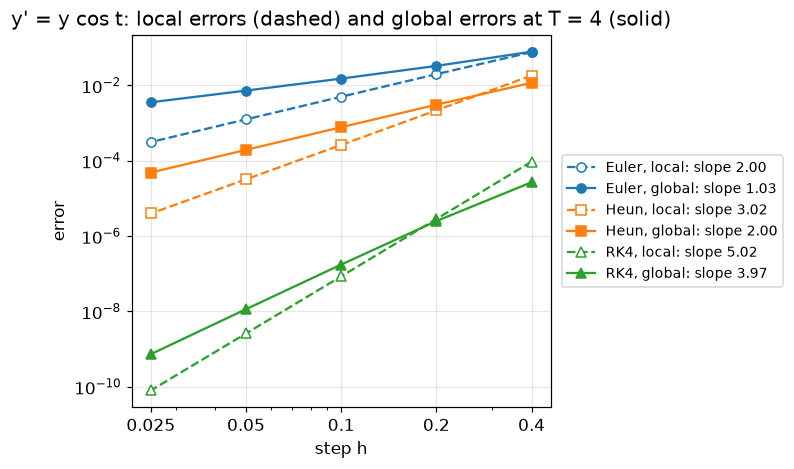

In [6]:
# drawing code: you can skip reading it
from matplotlib.ticker import NullFormatter

LOCAL_STYLE, GLOBAL_STYLE = "--", "-"
plot_steps = T_END / np.array(GLOBAL_STEPS)
slopes = {}
fig, ax = plt.subplots(figsize=LOGLOG_FIGURE)
for name, method in METHODS.items():
    local = [ol.local_error(method, cosine_rate, 0.0, COSINE_START, h, cosine_exact) for h in plot_steps]
    _, errors = ol.global_error(method, cosine_rate, (0.0, T_END), COSINE_START, cosine_exact, GLOBAL_STEPS)
    slopes[name] = (ol.observed_order(local)[-1], ol.observed_order(errors)[-1])
    ax.loglog(plot_steps, local, LOCAL_STYLE, marker=MARKERS[name], color=COLORS[name],
              markerfacecolor="white", label=f"{name}, local: slope {slopes[name][0]:.2f}")
    ax.loglog(plot_steps, errors, GLOBAL_STYLE, marker=MARKERS[name], color=COLORS[name],
              label=f"{name}, global: slope {slopes[name][1]:.2f}")
ax.set_xticks(plot_steps, [f"{h:g}" for h in plot_steps])      # the five steps, written plainly
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("step h")
ax.set_ylabel("error")
ax.set_title("y' = y cos t: local errors (dashed) and global errors at T = 4 (solid)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()
for name, (local_slope, global_slope) in slopes.items():   # the slopes are the orders p + 1 and p
    assert abs(local_slope - (ORDERS[name] + 1)) < ORDER_WINDOW
    assert abs(global_slope - ORDERS[name]) < ORDER_WINDOW

*The plot shows* six straight lines, two for each method in its own color: the dashed line of the local
error is always steeper than the solid line of the global error, by one. The slopes are about 2 and 1
for Euler, 3 and 2 for Heun, 5 and 4 for RK4. At $h = 0.025$ RK4's global error is below
$10^{-9}$, Euler's about $4 \cdot 10^{-3}$. (At the largest steps the local errors of Heun ($h = 0.4$) and
RK4 ($h = 0.4$ and $0.2$) are even above their global errors: one first step can be worse than the whole
run, whose errors partly cancel. The slopes are what matter.)

## 3. A convergence study on a system

(The practical exercise of Session 29.) **The spring** $x'' + 4x = 0$, $x(0) = 1$, $x'(0) = 0$ (notebook
07 with $m = 1$, $k = 4$, no damping) has the exact solution $x = \cos 2t$. With the velocity $v = x'$
it is the system $x' = v$, $v' = -4x$ (notebook 17). The same code solves it: in Lebl's words (Section
3.1.2), "We simply treat the dependent variable not as a number but as a vector." The function `f`
returns the pair $(x', v')$, and `component=0` asks `ol.global_error` for the error of $x$ alone.

The error is measured at $T = 5$. At a whole number of periods (the period is $\pi$), $x = \cos 2t$ is at
its top, where a small delay of the computed oscillation hardly changes $x$: only the error of its size
shows, and for Heun and RK4 that error is one power of $h$ smaller, so their errors of $x$ there fall like
$h^3$ and $h^5$ and the orders 2 and 4 would not be seen. $T = 5$ avoids it.

In [7]:
SPRING_RATE = 4.0                           # x'' + 4x = 0
SPRING_END = 5.0                            # T
SPRING_STEPS = (25, 50, 100, 200, 400, 800)
SPRING_START = [1.0, 0.0]                   # (x(0), v(0))
POWERS_AGREEMENT = 1e-6


def spring_rate(t, u):
    x, v = u                                # u is the pair (x, v): this line names its two parts
    return np.array([v, -SPRING_RATE * x])  # (x', v') = (v, -4x)


def spring_exact(t):
    return np.array([np.cos(2 * t), -2 * np.sin(2 * t)])     # (x, v) = (cos 2t, -2 sin 2t)


spring_errors = {}
print("   N" + "".join(f"{name:>12}" for name in METHODS))
for name, method in METHODS.items():
    _, spring_errors[name] = ol.global_error(method, spring_rate, (0.0, SPRING_END), SPRING_START,
                                             spring_exact, SPRING_STEPS, component=0)
for index, n in enumerate(SPRING_STEPS):
    print(f"{n:4d}" + "".join(f"{spring_errors[name][index]:12.2e}" for name in METHODS))
print("observed orders, last pair:", {name: round(float(ol.observed_order(errors)[-1]), 2)
                                       for name, errors in spring_errors.items()})

   N       Euler        Heun         RK4
  25    5.53e+00    1.07e-01    5.08e-04
  50    1.57e+00    2.96e-02    5.29e-05
 100    5.70e-01    8.12e-03    3.94e-06
 200    2.44e-01    2.14e-03    2.65e-07
 400    1.13e-01    5.51e-04    1.71e-08
 800    5.44e-02    1.40e-04    1.09e-09
observed orders, last pair: {'Euler': 1.05, 'Heun': 1.98, 'RK4': 3.98}


In [8]:
# checking code: you can skip reading it. On this linear system each step of each method multiplies
# (x, v) by one fixed matrix (Euler: I + hA), so N steps are its N-th power: an independent computation.
SPRING_MATRIX = np.array([[0.0, 1.0], [-SPRING_RATE, 0.0]])


TAYLOR_TERMS = {"Euler": 2, "Heun": 3, "RK4": 5}     # the terms of e^(hA) that each method keeps


def step_matrix(name, h):
    M = h * SPRING_MATRIX
    terms = [np.eye(2), M, M @ M / 2, M @ M @ M / 6, M @ M @ M @ M / 24]   # Taylor's terms of e^(hA)
    return sum(terms[:TAYLOR_TERMS[name]])


def x_by_powers(name, n, t_end=SPRING_END):
    return (np.linalg.matrix_power(step_matrix(name, t_end / n), n) @ SPRING_START)[0]


for name in METHODS:
    by_powers = [abs(x_by_powers(name, n) - np.cos(2 * SPRING_END)) for n in SPRING_STEPS]
    assert np.allclose(spring_errors[name], by_powers, rtol=POWERS_AGREEMENT), name

*The table shows* the three columns falling: Euler's error from 5.5 (worse than useless: $|x| \le 1$) to
$5.4 \cdot 10^{-2}$, Heun's from 0.11 to $1.4 \cdot 10^{-4}$, RK4's from $5.1 \cdot 10^{-4}$ to
$1.1 \cdot 10^{-9}$; the last observed orders are 1.05, 1.98 and 3.98. A system changes nothing in the
orders.

**Cost against accuracy.** (At home.) A step of RK4 costs 4 evaluations of $f$, one of Euler only 1
(in large problems almost all the time goes into computing $f$). Is RK4 worth it? The fair comparison is
the error against the total work, $N$ times the evaluations per step.

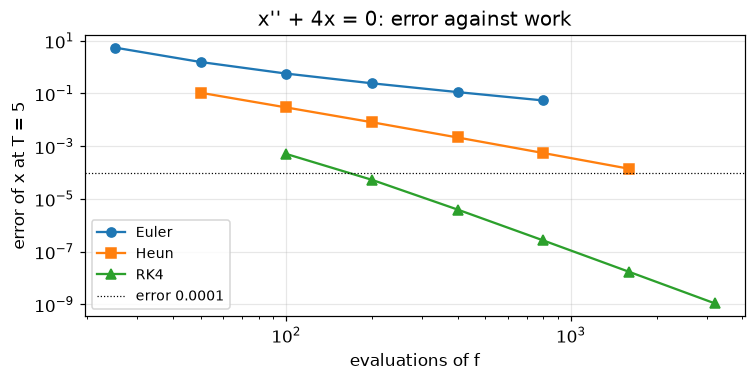

Euler:  419566 steps,  419566 evaluations of f for an error below 0.0001
Heun :     947 steps,    1894 evaluations of f for an error below 0.0001
RK4  :      42 steps,     168 evaluations of f for an error below 0.0001


In [9]:
TARGET = 1e-4                               # the accuracy asked for: the error of x at T = 5
fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
for name in METHODS:
    work = EVALUATIONS[name] * np.array(SPRING_STEPS)
    ax.loglog(work, spring_errors[name], "-", marker=MARKERS[name], color=COLORS[name], label=name)
ax.axhline(TARGET, color="black", linewidth=0.8, linestyle=":", label=f"error {TARGET:g}")
ax.set_xlabel("evaluations of f")
ax.set_ylabel("error of x at T = 5")
ax.set_title("x'' + 4x = 0: error against work")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()


# the smallest N with an error below TARGET (read what it prints; you can skip how it searches): by the
# matrix powers above; the errors fall steadily here, so one N is too few and the next is enough
def first_enough(name, low, high):
    while high - low > 1:                   # halve the interval [low, high] until the two are neighbours
        middle = (low + high) // 2
        if abs(x_by_powers(name, middle) - np.cos(2 * SPRING_END)) < TARGET:
            high = middle
        else:
            low = middle
    return high


SEARCH_RANGE = (1, 10 ** 6)
for name in METHODS:
    n = first_enough(name, *SEARCH_RANGE)
    print(f"{name:5s}: {n:7d} steps, {EVALUATIONS[name] * n:7d} evaluations of f for an error below "
          f"{TARGET:g}")

*The plot shows* the three lines with their slopes; the dotted line is the error $10^{-4}$. RK4 crosses it
on the left, after fewer than 200 evaluations; Heun's line ends just above it (1600 evaluations), and the
numbers say it crosses at about 1900; Euler's line has not reached it at the right end, and the numbers
say that it needs about 420 000 evaluations: **about 2500 times the work of RK4**. That is why RK4, and
solvers like it, are the usual choice.

**Euler's wrong energy.** (At home.) The energy of the spring (notebook 07), $\frac12v^2 + \frac12 \cdot
4x^2$, is $2\,(x^2 + (v/2)^2)$ and stays fixed: the point $(a, b) = (x, v/2) = (\cos 2t, -\sin 2t)$ goes
round the circle of radius 1. Euler's step is $x_{\text{new}} = x + hv$, $v_{\text{new}} = v - 4hx$, that
is $a_{\text{new}} = a + 2hb$, $b_{\text{new}} = b - 2ha$. Then $a_{\text{new}}^2 + b_{\text{new}}^2 =
a^2 + 4hab + 4h^2b^2 + b^2 - 4hab + 4h^2a^2 = (1 + 4h^2)(a^2 + b^2)$: the radius is multiplied by
$\sqrt{1 + 4h^2}$ at every step, so after two periods ($t = 2\pi$) with $N = 40$ steps
($h = 2\pi/40 = 0.157$) by $(\sqrt{1 + 4h^2})^{40} = (1 + 4h^2)^{20} = 6.57$.

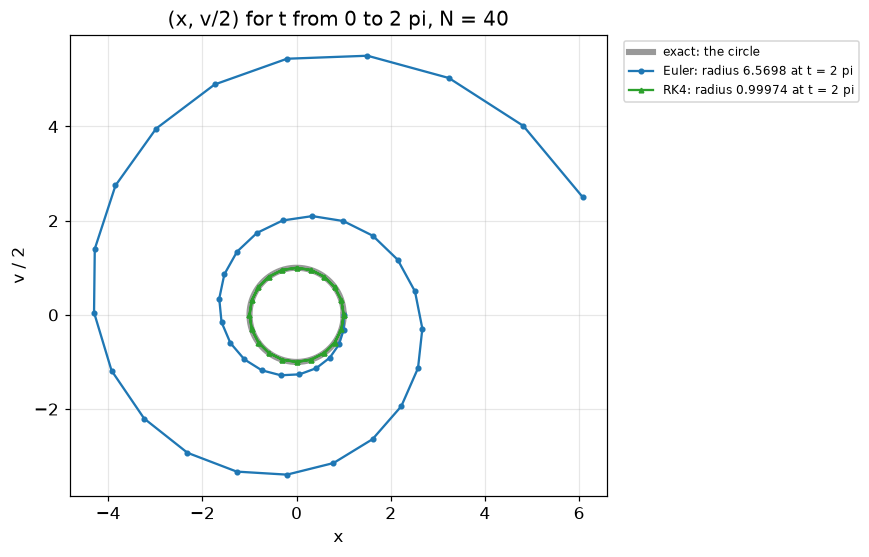

Euler's radius 6.5698, the formula 6.5698; RK4's radius 0.99974


In [10]:
ENERGY_END = 2 * np.pi                      # two periods of cos 2t
ENERGY_STEPS = 40
h_energy = ENERGY_END / ENERGY_STEPS
fig, ax = plt.subplots(figsize=ENERGY_FIGURE)
circle = np.linspace(0.0, ENERGY_END, GRID_POINTS)
ax.plot(np.cos(circle), np.sin(circle), "-", color="0.6", linewidth=4, zorder=0, label="exact: the circle")
radius = {}
for name in ("Euler", "RK4"):
    _, states = METHODS[name](spring_rate, (0.0, ENERGY_END), SPRING_START, h_energy)
    x_values, half_v = states[:, 0], states[:, 1] / 2
    radius[name] = float(np.hypot(x_values[-1], half_v[-1]))
    ax.plot(x_values, half_v, "-", marker=MARKERS[name], markersize=3, color=COLORS[name],
            label=f"{name}: radius {radius[name]:.5g} at t = 2 pi")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("v / 2")
ax.set_title(f"(x, v/2) for t from 0 to 2 pi, N = {ENERGY_STEPS}")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8)
plt.tight_layout()
plt.show()
predicted = (1 + 4 * h_energy ** 2) ** (ENERGY_STEPS / 2)     # sqrt(1 + 4h^2) at each of the 40 steps
print(f"Euler's radius {radius['Euler']:.4f}, the formula {predicted:.4f}; RK4's radius {radius['RK4']:.5f}")
assert np.isclose(radius["Euler"], predicted, rtol=AGREEMENT)

*The plot shows* Euler's points spiralling outwards from $(1, 0)$, twice round, to radius 6.57, while
RK4's points sit on the grey circle (radius 0.99974). Euler's method adds energy to a spring that has no
source of energy: a wrong solution that looks like a growing oscillation.

**Slider 1: how many steps?** The slider sets $N$; the plot shows $x(t)$ by the three methods and
$\cos 2t$, and the title the errors of $x$ at $T = 5$. Before moving it: with how many steps does
Euler's error of $x$ at $T = 5$ fall below 0.01? And RK4's? (Guess first, from the table above: Euler
has order 1, so $N$ times the error stays about the same; start from $800 \times 0.054$. To reach a
value, click the number to the right of the slider and type it.)

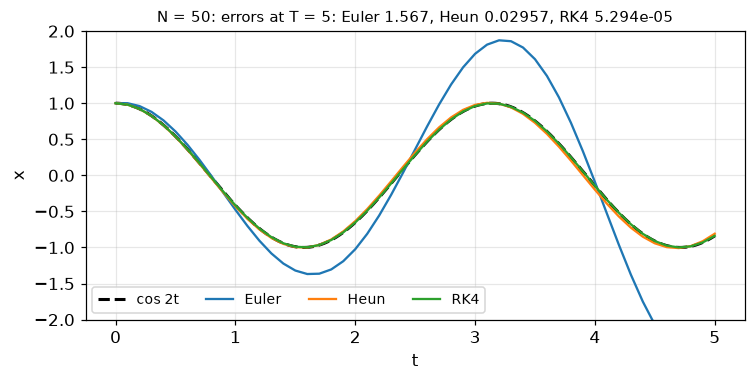

In [11]:
DEFAULT_N_1 = 50
N_RANGE_1 = (5, 5000, 1)                    # minimum, maximum, step
HEIGHT_1 = (-2.0, 2.0)


def plot_spring(n=DEFAULT_N_1):
    h = SPRING_END / n
    grid = np.linspace(0.0, SPRING_END, GRID_POINTS)
    fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
    ax.plot(grid, np.cos(2 * grid), "--", color="black", linewidth=2, label="cos 2t")
    errors = []
    for name, method in METHODS.items():
        times, states = method(spring_rate, (0.0, SPRING_END), SPRING_START, h)
        ax.plot(times, states[:, 0], "-", color=COLORS[name], linewidth=1.5, label=name)
        errors.append(f"{name} {abs(states[-1, 0] - np.cos(2 * SPRING_END)):.4g}")
    ax.set_ylim(*HEIGHT_1)
    ax.set_xlabel("t")
    ax.set_ylabel("x")
    ax.set_title(f"N = {n}: errors at T = 5: " + ", ".join(errors), fontsize=10)
    ax.legend(loc="lower left", ncols=4)
    plt.tight_layout()
    plt.show()


plot_spring()

In [12]:
interact(plot_spring, n=IntSlider(value=DEFAULT_N_1, min=N_RANGE_1[0], max=N_RANGE_1[1], step=N_RANGE_1[2],
                                  description="N", continuous_update=False));

interactive(children=(IntSlider(value=50, continuous_update=False, description='N', max=5000, min=5), Output()...

*The static plot shows*, for $N = 50$, RK4 on top of $\cos 2t$, Heun close to it, and Euler's
oscillation growing until it leaves the picture: its error at $T = 5$ is 1.6. (With very few steps,
$N = 5$, even Heun's values run away.)

(Answer: Euler needs **4225 steps**; RK4 only **12** (Heun 90). Order 1 means that the error shrinks only
as fast as $N$ grows: from 0.054 at $N = 800$ to 0.01 takes more than 5 times as many steps.)

In [13]:
# checking code: you can skip reading it; read what it prints. The errors at every position of the
# slider, by the matrix powers above (checked against the methods themselves at the answers)
ACCURACY_1 = 0.01
ANSWER_1 = {"Euler": 4225, "Heun": 90, "RK4": 12}
positions = range(N_RANGE_1[0], N_RANGE_1[1] + 1, N_RANGE_1[2])
for name in METHODS:
    errors = np.array([abs(x_by_powers(name, n) - np.cos(2 * SPRING_END)) for n in positions])
    index = int(np.argmax(errors < ACCURACY_1))
    first = positions[index]
    stays = bool(np.all(errors[index:] < ACCURACY_1))
    print(f"{name:5s}: below {ACCURACY_1} from N = {first} on (and for every larger N on the slider: "
          f"{stays})")
    assert first == ANSWER_1[name] and stays, "slider 1: the answer is not as the text says"
for n in (ANSWER_1["Euler"] - 1, ANSWER_1["Euler"]):
    by_euler = ol.euler(spring_rate, (0.0, SPRING_END), SPRING_START, SPRING_END / n)[1][-1, 0]
    assert np.isclose(by_euler, x_by_powers("Euler", n), rtol=LOOSE_AGREEMENT)

Euler: below 0.01 from N = 4225 on (and for every larger N on the slider: True)


Heun : below 0.01 from N = 90 on (and for every larger N on the slider: True)
RK4  : below 0.01 from N = 12 on (and for every larger N on the slider: True)


## 4. Stiffness and an implicit method

**The problem.** $y' = -100\,(y - \sin t)$, $y(0) = 1$: $y$ is pulled towards $\sin t$, very strongly
(rate 100). The solution (a linear equation, notebook 11) is

$$ y = C\,e^{-100t} + \frac{10000\sin t - 100\cos t}{10001}, \qquad C = 1 + \frac{100}{10001}. $$

The first term is below 0.01 from $t = 0.05$ on; then $y$ follows a slowly varying curve, almost
$\sin t$. **Euler's method** gives $y_{n+1} = y_n - 100h\,(y_n - \sin t_n)$, so
$y_{n+1} - \sin t_n = (1 - 100h)(y_n - \sin t_n)$: at each step the gap between $y$ and $\sin t$ (almost
the slow curve) is multiplied by $1 - 100h$ (and the small change of $\sin t$ during one step is added),
exactly as
$y' = -5y$ was multiplied by $1 - 5h$ in notebook 04, Section 6. A method is **stable** with a step $h$
when such gaps do not grow. Here the gap shrinks only if $|1 - 100h| < 1$, that is
$-1 < 1 - 100h < 1$, so $0 < h < 0.02$, **for the whole interval**, although after $t = 0.05$ the
solution is as smooth as $\sin t$. When stability, not accuracy, forces the small step, the
problem is called **stiff** (Lebl, Section 1.7: "Such problems are sometimes called stiff").

In [14]:
STIFF_RATE = 100.0                          # y' = -100 (y - sin t)
STIFF_END = 1.5
STIFF_START = 1.0                           # y(0) = 1


def stiff_rate(t, y):
    return -STIFF_RATE * (y - np.sin(t))


def stiff_exact(t):
    slow = (STIFF_RATE ** 2 * np.sin(t) - STIFF_RATE * np.cos(t)) / (STIFF_RATE ** 2 + 1)
    return (1 + STIFF_RATE / (STIFF_RATE ** 2 + 1)) * np.exp(-STIFF_RATE * t) + slow


STIFF_STEPS = (0.1, 0.05, 0.025, 0.0125)
print("     h    1 - 100h   Euler's error at t = 1.5   backward Euler's")
backward_errors = []
for h in STIFF_STEPS:
    euler_end = ol.euler(stiff_rate, (0.0, STIFF_END), STIFF_START, h)[1][-1]
    times, values = ol.backward_euler(stiff_rate, (0.0, STIFF_END), STIFF_START, h)
    backward_errors.append(abs(values[-1] - stiff_exact(STIFF_END)))
    print(f"{h:6.4f} {1 - STIFF_RATE * h:9.2f} {abs(euler_end - stiff_exact(STIFF_END)):24.2e} "
          f"{backward_errors[-1]:18.2e}")

     h    1 - 100h   Euler's error at t = 1.5   backward Euler's
0.1000     -9.00                 2.08e+14           4.96e-04
0.0500     -4.00                 1.16e+18           2.48e-04
0.0250     -1.50                 3.71e+10           1.24e-04
0.0125     -0.25                 6.23e-05           6.22e-05


*The table shows* Euler's error at $t = 1.5$ as an absurd $10^{14}$, $10^{18}$, $10^{10}$ for the three
steps above 0.02, and $6 \cdot 10^{-5}$ for $h = 0.0125$. ($h = 0.05$ is worse than $h = 0.1$: 30 steps
with factor $-4$, $4^{30} \approx 10^{18}$, against 15 steps with factor $-9$, $9^{15} \approx 2 \cdot
10^{14}$.) The last column is a method that stays stable at every one of these steps:

**Backward Euler** takes the slope at the END of the step:

$$ y_{n+1} = y_n + h\,f(t_{n+1}, y_{n+1}). $$

The unknown $y_{n+1}$ is on both sides, so **each step must solve an equation** for it: that is what
*implicit* means. (Euler's formula is *explicit*: its right side has only numbers already known. In
backward Euler's, $y_{n+1}$ sits inside $f$, as in $y_1 = 1 + 0.5 \cdot (-3y_1)$ of Exercise 2(b).)
With $f(t, y) = -100\,(y - \sin t)$: $y_{n+1} = y_n - 100h\,(y_{n+1} - \sin t_{n+1})$; move the
$y_{n+1}$ terms to the left: $y_{n+1}(1 + 100h) = y_n + 100h\sin t_{n+1}$, so

$$ y_{n+1} = \frac{y_n + 100h\sin t_{n+1}}{1 + 100h}. $$

On the test equation $y' = \lambda y$ it gives $y_{n+1} = y_n + h\lambda\,y_{n+1}$, so it multiplies by
$\frac{1}{1 - h\lambda}$; for $\lambda = -100$ that is $\frac{1}{1 + 100h}$, less than 1 for every
$h > 0$: **stable for every step** (for every $\lambda < 0$). It is not more accurate than Euler: it
has order 1 too (its errors in the table halve with $h$: $5.0 \cdot 10^{-4}$, $2.5 \cdot 10^{-4}$, ...).
It wins on stability, not on accuracy. For an $f$ that is not linear, `ol.backward_euler(f, (0, T), y0,
h)` solves the equation by the computer at every step (Newton's method), so you never solve it by hand.

In [15]:
H_BACKWARD = 0.1
times, values = ol.backward_euler(stiff_rate, (0.0, STIFF_END), 1.0, H_BACKWARD)
by_formula = [STIFF_START]                  # the formula above, step by step
for t_next in times[1:]:
    by_formula.append((by_formula[-1] + STIFF_RATE * H_BACKWARD * np.sin(t_next))
                      / (1 + STIFF_RATE * H_BACKWARD))
print("t        :", np.round(times[:6], 2))
print("backward :", np.round(values[:6], 5))
print("exact    :", np.round(stiff_exact(times[:6]), 5))
HALVING, HALVING_DIGITS = 2, 0.01            # order 1: the error is halved with h, to 1%
assert np.allclose(values, by_formula, rtol=AGREEMENT)
assert np.allclose(np.array(backward_errors[:-1]) / backward_errors[1:], HALVING, rtol=HALVING_DIGITS)

t        : [0.  0.1 0.2 0.3 0.4 0.5]
backward : [1.      0.18167 0.19712 0.28658 0.38007 0.47039]
exact    : [1.      0.08992 0.18885 0.28594 0.38017 0.4706 ]


*The table shows* backward Euler with $h = 0.1$, five times Euler's limit: no jump, but in the fast start
it is late (0.18 against the exact 0.09 at $t = 0.1$); from $t = 0.3$ on it agrees to about 3 decimals.
Stable does not mean accurate: a large step cannot follow the fast part; it only does not blow up.

**Slider 2: Euler against backward Euler.** The slider sets the step $h$; the plot shows both methods
and the exact solution on $0 \le t \le 1.5$, and the title the factors by which each method multiplies
the gap. Before moving it: **Euler with $h = 0.03$: will it follow $\sin t$?**

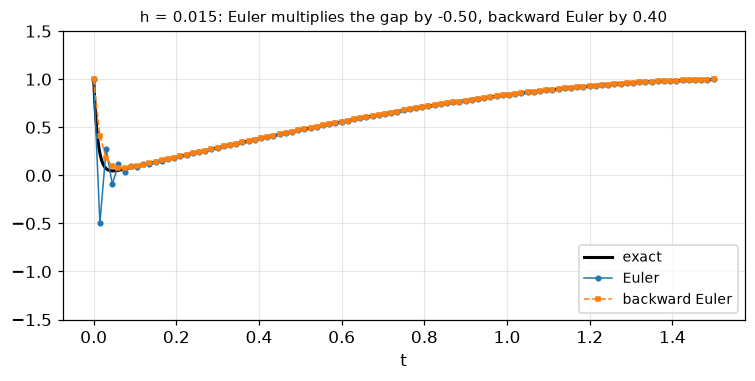

In [16]:
DEFAULT_H_2 = 0.015
H_RANGE_2 = (0.005, 0.1, 0.005)             # minimum, maximum, step
HEIGHT_2 = (-1.5, 1.5)


def stiff_run(method, h):
    n = max(1, int(round(STIFF_END / h)))   # a whole number of steps, ending near t = 1.5
    return method(stiff_rate, (0.0, n * h), STIFF_START, h)


def plot_stiff(h=DEFAULT_H_2):
    grid = np.linspace(0.0, STIFF_END, GRID_POINTS)
    fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
    ax.plot(grid, stiff_exact(grid), "-", color="black", linewidth=2, label="exact")
    times, values = stiff_run(ol.euler, h)
    largest = np.max(np.abs(values))
    note = f" (values up to {largest:.2g}, off the picture)" if largest > HEIGHT_2[1] else ""
    ax.plot(times, values, "o-", color=COLORS["Euler"], markersize=3, linewidth=1, label="Euler" + note)
    times, values = stiff_run(ol.backward_euler, h)
    ax.plot(times, values, "s--", color=COLORS["Heun"], markersize=3, linewidth=1, label="backward Euler")
    ax.set_ylim(*HEIGHT_2)
    ax.set_xlabel("t")
    ax.set_title(f"h = {h:.3f}: Euler multiplies the gap by {1 - STIFF_RATE * h:+.2f}, "
                 f"backward Euler by {1 / (1 + STIFF_RATE * h):.2f}", fontsize=10)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


plot_stiff()

In [17]:
interact(plot_stiff, h=FloatSlider(value=DEFAULT_H_2, min=H_RANGE_2[0], max=H_RANGE_2[1], step=H_RANGE_2[2],
                                   readout_format=".3f", description="h", continuous_update=False));

interactive(children=(FloatSlider(value=0.015, continuous_update=False, description='h', max=0.1, min=0.005, r...

*The static plot shows*, for $h = 0.015$, Euler's first values jumping below and above the exact fall
(the factor $-0.5$ changes the sign of the gap at every step, and halves it), backward Euler falling more
slowly than the exact solution; by $t = 0.1$ both have joined it, and all three follow the slow rise
that is almost $\sin t$.

(Answer: **no**. With $h = 0.03$ Euler's factor is $1 - 3 = -2$: the gap doubles and changes sign at
every step, and by $t = 1.5$ the values are about $10^{15}$. Backward Euler's factor is
$\frac{1}{4}$, and it follows the solution. At $h = 0.02$ Euler's factor is exactly $-1$: the gap neither
grows nor shrinks.)

In [18]:
# checking code: you can skip reading it; read what it prints. Every position of the slider: Euler ends
# near the solution when |1 - 100h| < 1, far from it when |1 - 100h| > 1, and with its first gap kept when
# |1 - 100h| = 1; backward Euler always ends near
NEAR, FAR = 0.01, 1.0
INITIAL_GAP = 1 + STIFF_RATE / (STIFF_RATE ** 2 + 1)      # y(0) minus the slow curve at 0: the C above
steps_2 = H_RANGE_2[0] + H_RANGE_2[2] * np.arange(round((H_RANGE_2[1] - H_RANGE_2[0]) / H_RANGE_2[2]) + 1)
for h in steps_2:
    euler_times, euler_values = stiff_run(ol.euler, h)
    back_times, back_values = stiff_run(ol.backward_euler, h)
    euler_gap = abs(euler_values[-1] - stiff_exact(euler_times[-1]))
    back_gap = abs(back_values[-1] - stiff_exact(back_times[-1]))
    factor = abs(1 - STIFF_RATE * h)
    assert back_gap < NEAR, "slider 2: backward Euler is not as the text says"
    if factor < 1 - NEAR:
        euler_as_said = euler_gap < NEAR
    elif factor > 1 + NEAR:
        euler_as_said = euler_gap > FAR
    else:                                   # |1 - 100h| = 1: the gap neither shrinks nor grows
        euler_as_said = abs(euler_gap - INITIAL_GAP) < NEAR
    assert euler_as_said, "slider 2: Euler is not as the text says"
QUESTION_H_2 = 0.03                         # the step of the slider question
print(f"{len(steps_2)} positions checked; with h = {QUESTION_H_2:g} Euler ends at "
      f"{stiff_run(ol.euler, QUESTION_H_2)[1][-1]:.1e}")

20 positions checked; with h = 0.03 Euler ends at 1.1e+15


**The professional version.** `solve_ivp` has implicit methods too: `"BDF"` (a relative of backward
Euler) and `"Radau"`. On the same problem up to $t = 10$, with `rtol=1e-4`:

In [19]:
LONG_END = 10.0
SOLVER_RTOL = 1e-4
counts = {}
for solver in ("RK45", "BDF"):
    result = solve_ivp(stiff_rate, (0.0, LONG_END), [STIFF_START], method=solver, rtol=SOLVER_RTOL)
    counts[solver] = (result.t.size - 1, result.nfev)
    error = abs(result.y[0, -1] - stiff_exact(LONG_END))
    print(f"{solver:5s}: {counts[solver][0]:4d} steps, {counts[solver][1]:5d} evaluations of f, "
          f"error at t = 10: {error:.1e}")
RK45_STEPS_RATIO, RK45_WORK_RATIO = 2, 5     # at least (the text says about 3 and 8)
assert (counts["RK45"][0] > RK45_STEPS_RATIO * counts["BDF"][0]
        and counts["RK45"][1] > RK45_WORK_RATIO * counts["BDF"][1])

RK45 :  365 steps,  2222 evaluations of f, error at t = 10: 1.2e-05
BDF  :  117 steps,   283 evaluations of f, error at t = 10: 7.4e-07


*The table shows* RK45, an explicit method like RK4, taking about three times as many steps and about
eight times as many evaluations as BDF: its steps are kept small by stability, for the whole time, not
by the smoothness of the solution. This is the kind of problem of notebook 04's "Going further", C,
$y' = -1000\,(y - \cos t)$, now with the idea that cures it.

## 5. How `solve_ivp` chooses its step

Without the exact solution, how can a solver know the error of a step? **Two methods, one step:**
from the same point, take one step with Euler and one with Heun. Both start with the slope
$k_1 = f(t, y)$. Euler: $y + hk_1$. Heun: $y + \frac{h}{2}(k_1 + k_2)$ with $k_2 = f(t + h,\ y + hk_1)$.
Their difference is $\frac{h}{2}(k_2 - k_1)$. Why it estimates Euler's error: Euler $-$ exact $=$
(Euler $-$ Heun) $+$ (Heun $-$ exact), and for small $h$ the last bracket (size $h^3$) is much smaller
than the first (size $h^2$). Euler's step is *embedded* in Heun's (it uses the same $k_1$), so the
estimate costs no extra evaluation of $f$. `ol.embedded_step(f, t, y, h)` returns Heun's value and the
estimate $|\text{Heun} - \text{Euler}|$. Checked against the true local error on $y' = y\cos t$:

In [20]:
ESTIMATE_AGREEMENT = 0.02                   # at the smallest h, the estimate within 2% of the true error
print("     h    estimate   true local error of Euler")
for h in LOCAL_STEPS:
    _, estimate = ol.embedded_step(cosine_rate, 0.0, COSINE_START, h)
    true_error = ol.local_error(ol.euler, cosine_rate, 0.0, COSINE_START, h, cosine_exact)
    print(f"{h:6.3f} {estimate:11.2e} {true_error:14.2e}")
assert abs(estimate / true_error - 1) < ESTIMATE_AGREEMENT     # (the last h)

     h    estimate   true local error of Euler
 0.200    1.76e-02       1.98e-02
 0.100    4.73e-03       4.99e-03
 0.050    1.22e-03       1.25e-03
 0.025    3.08e-04       3.12e-04


*The table shows* the estimate below the true error, by 11% at $h = 0.2$ and by 1% at $h = 0.025$: good
enough to steer the step.

**A small adaptive loop.** Ask that the estimate of every step stay below a tolerance. If it does, keep
the step (with Heun's value) and try a step 1.2 times larger; if not, stay where you are and halve the
step. (The value kept is Heun's, whose error is usually much smaller than the estimate, which is
Euler's: that is on the safe side, but only for small steps; with a large step the estimate can even be
0.) The steps then follow the solution: by Taylor's formula the estimate is about $\frac{h^2}{2}|y''|$,
and $\frac{h^2}{2}|y''| = \text{tolerance}$ gives $h^2 = 2 \cdot \text{tolerance} / |y''|$: small steps
where $y$ bends a lot, large ones where it is almost straight.

In [21]:
TOLERANCE = 1e-3                            # the largest estimate accepted for one step (try 1e-4)
GROWTH = 1.2                                # after a good step, try a step 1.2 times larger
FIRST_STEP = 0.1
ROUNDING = 1e-12                            # t + h may miss T by 1e-16 (notebook 08): closer counts as T
MAX_TRIES = 50_000                          # a smaller TOLERANCE needs more steps: stop here

t_now, y_now, h = 0.0, COSINE_START, FIRST_STEP
kept_times, kept_values, kept_steps, rejected = [t_now], [y_now], [], 0
while t_now < T_END - ROUNDING and len(kept_steps) + rejected < MAX_TRIES:     # until T = 4
    h = min(h, T_END - t_now)               # the last step lands exactly on T
    heun_value, estimate = ol.embedded_step(cosine_rate, t_now, y_now, h)
    if estimate <= TOLERANCE:               # a good step: keep it, move on, try a larger one
        kept_steps.append(h)
        t_now, y_now = t_now + h, heun_value
        kept_times.append(t_now)
        kept_values.append(y_now)
        h = GROWTH * h
    else:                                   # too large: stay here and halve the step
        h = h / 2
        rejected += 1
if t_now < T_END - ROUNDING:
    print(f"stopped at t = {t_now:.3f} after {MAX_TRIES} tries: TOLERANCE {TOLERANCE:g} is too small for "
          "this loop (solve_ivp below does the same work much faster)")
else:
    print(f"{len(kept_steps)} steps kept, {rejected} refused; steps from {min(kept_steps):.3f} to "
          f"{max(kept_steps):.3f}; error at T = 4: {abs(y_now - cosine_exact(T_END)):.1e}")

124 steps kept, 33 refused; steps from 0.014 to 0.096; error at T = 4: 8.5e-05


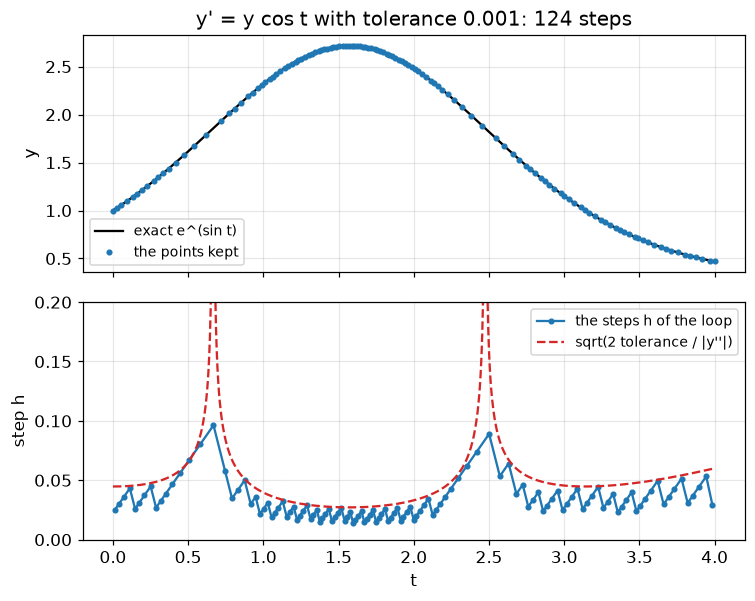

In [22]:
# drawing code: you can skip reading it
starts, kept = np.array(kept_times[:-1]), np.array(kept_steps)
grid = np.linspace(0.0, T_END, GRID_POINTS)
bending = np.abs((np.cos(grid) ** 2 - np.sin(grid)) * np.exp(np.sin(grid)))      # |y''|
STEP_WINDOW = (0.0, 0.2)
fig, (top, bottom) = plt.subplots(2, 1, figsize=TWO_PANELS, sharex=True)
top.plot(grid, cosine_exact(grid), "-", color="black", linewidth=1.5, label="exact e^(sin t)")
top.plot(kept_times, kept_values, "o", color="C0", markersize=3, label="the points kept")
top.set_ylabel("y")
top.legend(loc="lower left")
bottom.plot(starts + kept / 2, kept, "o-", color="C0", markersize=3, label="the steps h of the loop")
with np.errstate(divide="ignore"):
    bottom.plot(grid, np.sqrt(2 * TOLERANCE / bending), "--", color="C3", label="sqrt(2 tolerance / |y''|)")
bottom.set_ylim(*STEP_WINDOW)
bottom.set_xlabel("t")
bottom.set_ylabel("step h")
bottom.legend(loc="upper right")
top.set_title(f"y' = y cos t with tolerance {TOLERANCE:g}: {len(kept_steps)} steps")
plt.tight_layout()
plt.show()

*The plot shows*, on top, the points kept by the loop on the curve $e^{\sin t}$; their density is easier
to see below, in the steps: from about 0.014 near $t = 1.6$, over the hump, to about 0.1 near $t = 0.6$
and $t = 2.5$, where the curve is almost straight ($y'' = 0$). The dashed curve of Taylor's estimate has
the same shape, a little above the steps (it is infinite where $y'' = 0$: there any step passes, and the
growth factor 1.2 is what limits the loop); the saw-teeth are the rule at work (grow by 1.2, refused,
halved).

**What `solve_ivp` does.** Its default method, RK45, uses the same idea with a better pair: a method
of order 4 and one of order 5 from the same evaluations of $f$; their difference estimates the error,
and the step is chosen so that the estimate stays below `atol + rtol * |y|` (SciPy's documentation;
`atol` is a tolerance in absolute size, which matters where $y$ is near 0; here it is set tiny so that
`rtol` decides). A **tolerance is not the error**: it limits the estimate of the LOCAL error of each step;
the error at the end is the GLOBAL error, what all the steps add up to, carried along. Measured at
$T = 4$:

In [23]:
TOLERANCES = (1e-3, 1e-6, 1e-9)
SMALL_ATOL = 1e-12                          # so that rtol decides
print(" rtol   points   evaluations   error at T = 4")
for tolerance in TOLERANCES:
    result = solve_ivp(cosine_rate, (0.0, T_END), [COSINE_START], rtol=tolerance, atol=SMALL_ATOL)
    error = abs(result.y[0, -1] - cosine_exact(T_END))
    print(f"{tolerance:5.0e} {result.t.size:6d} {result.nfev:12d} {error:16.1e}")

 rtol   points   evaluations   error at T = 4
1e-03      7           44          1.4e-04
1e-06     16          110          1.5e-07
1e-09     54          344          2.5e-10


*The table shows* 7, 16 and 54 points (points = steps + 1, the start included) and errors
$1.4 \cdot 10^{-4}$, $1.5 \cdot 10^{-7}$, $2.5 \cdot 10^{-10}$: smaller tolerances give smaller errors,
here below the tolerance, but nothing promises that (Exercise 4(iii) asks whether it holds for the
spring). Our loop needed 124 steps for its tolerance $10^{-3}$; RK45, with `rtol` $= 10^{-3}$
(relative to $|y|$, so a little looser here), needs 6, because a method of order 4-5 makes much smaller
local errors per step. To trust a result, solve again with a smaller tolerance
and compare, as notebook 04 says for $h$.

## 6. Where to go next

Session 30 gathers the course. In Projects 3 and 4 you use `solve_ivp`: choose the method (`"RK45"`;
`"BDF"` or `"Radau"` when the problem is stiff), give `rtol`, and check by solving again with a smaller
one. Left out here: multistep methods (BDF in full), error control for systems, and *symplectic*
methods, which keep the energy of a spring close to its true value for all time, where Euler's spiral did
not.

## 7. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

* (a) A method's global errors are $3.2 \cdot 10^{-3}$, $4.1 \cdot 10^{-4}$, $5.1 \cdot 10^{-5}$ for
  $h$, $h/2$, $h/4$. Its order (a whole number)?
* (b) Euler's global error is 0.02 with $N = 50$ steps. About how many steps give 0.005?
* (c) For $y' = -50\,(y - \cos t)$: is Euler's method stable with $h = 0.03$? With $h = 0.05$? (Answer
  True or False: is $|1 - 50h| < 1$?)
* (d) Does backward Euler have a higher order than Euler (True or False)?

In [24]:
my_order_1a = None              # a whole number
my_steps_1b = None              # a number of steps
my_stable_003 = None            # True or False
my_stable_005 = None            # True or False
my_higher_1d = None             # True or False
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ERRORS_1A = (3.2e-3, 4.1e-4, 5.1e-5)
order_1a = round(float(np.mean(ol.observed_order(ERRORS_1A))))      # log2 of the factors 7.8 and 8.0
ROUND_WINDOW = 0.5                          # a decimal this close to the order: not rounded yet
if close_to(my_order_1a, 2 ** order_1a):
    print("Exercise 1a: not yet (8 is the factor by which the error is divided: the order p has 2^p = 8)")
elif isinstance(my_order_1a, float) and 0 < abs(my_order_1a - order_1a) < ROUND_WINDOW:
    print("Exercise 1a: not yet (an order is a whole number: round it)")
else:
    ol.check("Exercise 1a", my_order_1a, order_1a)
N_1B, ERROR_1B, TARGET_1B = 50, 0.02, 0.005
expected_1b = N_1B * ERROR_1B / TARGET_1B                           # order 1: N grows as the error shrinks
if close_to(my_steps_1b, N_1B * np.sqrt(ERROR_1B / TARGET_1B)):
    print("Exercise 1b: not yet (that would be a method of order 2: for order 1, 4 times smaller needs "
          "4 times as many steps)")
else:
    ol.check("Exercise 1b", my_steps_1b, expected_1b)
RATE_1C = 50.0                              # y' = -50 (y - cos t)
STEPS_1C = (0.03, 0.05)
for mine, h in zip((my_stable_003, my_stable_005), STEPS_1C, strict=True):
    ol.check(f"Exercise 1c, h = {h:g}", mine, abs(1 - RATE_1C * h) < 1)
ol.check("Exercise 1d", my_higher_1d, False);

Exercise 1a: no answer yet (replace None with your value)
Exercise 1b: no answer yet (replace None with your value)
Exercise 1c, h = 0.03: no answer yet (replace None with your value)
Exercise 1c, h = 0.05: no answer yet (replace None with your value)
Exercise 1d: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** $y' = -2ty$, $y(0) = 1$, exact solution $y = e^{-t^2}$. One Euler step with $h = 0.1$: $y_1$; its
local error $|y_1 - e^{-0.01}|$; and Taylor's estimate $\frac{h^2}{2}|y''(0)|$. First step:
$y'' = (4t^2 - 2)\,e^{-t^2}$.

**(b)** $y' = -3y$, $y(0) = 1$, $h = 0.5$: one Euler step and one backward Euler step, against
$e^{-1.5} = 0.223$. Which method keeps the sign of the solution: `"Euler"`, `"backward Euler"`, `"both"`
or `"neither"`? First step: backward Euler's equation is $y_1 = 1 + 0.5 \cdot (-3y_1)$.

**(c)** With `ol.global_error`: the observed order of Heun's method on $y' = -2ty$, $y(0) = 1$, on
$0 \le t \le 2$, from $N = 80$ to $N = 160$ (two decimals). First step: complete `rate_2c` in the cell
below, run it, and copy the number it prints.

In [25]:
# Exercise 2(c): complete the right side, run this cell, copy the printed number into my_order_2c below
def rate_2c(t, y):
    return None                       # replace None with the right side of y' = -2 t y


def exact_2c(t):
    return np.exp(-t ** 2)            # the exact solution e^(-t^2)


if rate_2c(0.0, 1.0) is not None:
    _, errors_2c_mine = ol.global_error(ol.heun, rate_2c, (0.0, 2.0), 1.0, exact_2c, [80, 160])   # _: the h
    print("observed order:", ol.observed_order(errors_2c_mine)[0])   # [0]: the one number of the list

In [26]:
my_euler_2a = None              # a number
my_local_2a = None              # a number
my_taylor_2a = None             # a number
my_euler_2b = None              # a number
my_backward_2b = None           # a number
my_sign_2b = None               # one of the four words, in quotes
my_order_2c = None              # a number (printed by the cell above)
# ---- your answers go above this line; the lines below check them (nothing to change) ----

H_2A, H_2B, RATE_2B = 0.1, 0.5, -3.0
t_symbol = sp.symbols("t")
exact_2 = sp.exp(-t_symbol ** 2)
second_2a = float(exact_2.diff(t_symbol, 2).subs(t_symbol, 0))      # y''(0), by SymPy
ol.check("Exercise 2a, y_1", my_euler_2a, 1 + H_2A * (-2 * 0 * 1))
ol.check("Exercise 2a, local error", my_local_2a, abs(1 - np.exp(-H_2A ** 2)))
if close_to(my_taylor_2a, H_2A ** 2 / 2 * second_2a):
    print("Exercise 2a, Taylor: not yet (the size: take |y''(0)|, without its sign)")
else:
    ol.check("Exercise 2a, Taylor", my_taylor_2a, H_2A ** 2 / 2 * abs(second_2a))
ol.check("Exercise 2b, Euler", my_euler_2b, 1 + H_2B * RATE_2B)
if close_to(my_backward_2b, 1 / (1 + H_2B * RATE_2B)):
    print("Exercise 2b, backward Euler: not yet (a sign: y_1 = 1 - 1.5 y_1, so 2.5 y_1 = 1)")
else:
    ol.check("Exercise 2b, backward Euler", my_backward_2b, 1 / (1 - H_2B * RATE_2B))
ol.check_choice("Exercise 2b, the sign", my_sign_2b, "backward Euler",
                ("Euler", "backward Euler", "both", "neither"))
f_2c = sp.lambdify(t_symbol, exact_2)
SPAN_2C, START_2C, STEPS_2C, RATE_2C = (0.0, 2.0), 1.0, (80, 160), -2.0     # the statement of 2(c)
_, errors_2c = ol.global_error(ol.heun, lambda t, y: RATE_2C * t * y, SPAN_2C, START_2C, f_2c, STEPS_2C)
ORDER_TOLERANCE_2C = 0.005                  # the computed number to two decimals (2 alone is not enough)
order_2c = ol.observed_order(errors_2c)[0]
answer_2c = my_order_2c
if isinstance(answer_2c, (list, tuple, np.ndarray)) and np.size(answer_2c) == 1:
    answer_2c = np.ravel(answer_2c)[0]        # a list of one number, as observed_order returns
if close_to(answer_2c, ORDERS["Heun"]):
    print("Exercise 2c: not yet (2 is the order Heun should have; compute the observed one with the cell "
          "above)")
elif (isinstance(answer_2c, (int, float)) and not isinstance(answer_2c, bool)
      and ORDER_TOLERANCE_2C * order_2c < abs(answer_2c - order_2c) < ROUND_WINDOW / 10):
    print("Exercise 2c: not yet (close: copy the number printed by the cell above, to two decimals)")
else:
    ol.check("Exercise 2c", answer_2c, order_2c, tol=ORDER_TOLERANCE_2C)

Exercise 2a, y_1: no answer yet (replace None with your value)
Exercise 2a, local error: no answer yet (replace None with your value)
Exercise 2a, Taylor: no answer yet (replace None with your value)
Exercise 2b, Euler: no answer yet (replace None with your value)
Exercise 2b, backward Euler: no answer yet (replace None with your value)
Exercise 2b, the sign: no answer yet (replace None with your answer, a word in quotes)
Exercise 2c: no answer yet (replace None with your value)


### Exercise 3 - Fill in

**The midpoint method** takes the slope in the middle of the step:
$k_1 = f(t, y)$, $y_{n+1} = y_n + h\,f\!\left(t + \frac{h}{2},\ y_n + \frac{h}{2}k_1\right)$. Complete
`midpoint_step(f, t, y, h)` (its `y` is $y_n$) so that it returns $y_{n+1}$. The next cell runs it on
$y' = y\cos t$ and measures its global order with `ol.global_error` and its local order with
`ol.local_error`. Which orders do you expect?

In [27]:
def midpoint_step(f, t, y, h):
    k1 = None                   # replace None with the slope at the start, f(t, y)
    return None                 # replace None with the formula

In [28]:
def midpoint(f, t_span, y0, h):
    # the midpoint method from t0 to t1 with your step, called as ol.euler is (nothing to change here)
    n = int(round((t_span[1] - t_span[0]) / h))
    times = t_span[0] + h * np.arange(n + 1)
    values = [np.atleast_1d(np.asarray(y0, dtype=float))]
    for t_now in times[:-1]:
        values.append(np.atleast_1d(np.asarray(midpoint_step(f, t_now, values[-1], h), dtype=float)))
    values = np.array(values)
    return times, (values[:, 0] if values.shape[1] == 1 else values)


def check_midpoint():
    # one line: correct (with the two orders), or not yet with a reason; nothing here stops the cell
    try:
        trial = midpoint_step(cosine_rate, 0.0, np.array([COSINE_START]), H_BY_HAND)
        if trial is None:
            return "Exercise 3: no answer yet (complete midpoint_step)"
        _, errors = ol.global_error(midpoint, cosine_rate, (0.0, T_END), COSINE_START, cosine_exact,
                                    GLOBAL_STEPS)
        local = [ol.local_error(midpoint, cosine_rate, 0.0, COSINE_START, h, cosine_exact)
                 for h in LOCAL_STEPS]
    except Exception as problem:            # an error in the formula: say so, do not stop
        return f"Exercise 3: not yet (your step stopped with an error: {type(problem).__name__}: {problem})"
    half_way = COSINE_START + H_BY_HAND / 2 * cosine_rate(0.0, COSINE_START)       # y + (h/2) k_1
    middle = COSINE_START + H_BY_HAND * cosine_rate(H_BY_HAND / 2, half_way)
    global_order, local_order = ol.observed_order(errors)[-1], ol.observed_order(local)[-1]
    if np.allclose(trial, middle):
        return f"Exercise 3: correct (global order {global_order:.2f}, local order {local_order:.2f})"
    if np.allclose(trial, COSINE_START + H_BY_HAND * cosine_rate(0.0, COSINE_START)):
        return "Exercise 3: not yet (this is Euler's step: take the slope at the middle, t + h/2)"
    return f"Exercise 3: not yet (your step has global order {global_order:.2f}; check the formula)"


print(check_midpoint())

Exercise 3: no answer yet (complete midpoint_step)


### Exercise 4 - Explore

* (i) RK4 on $y' = y\cos t$ to $T = 4$ with $N = 10, 20, 40, \ldots, 20480$ steps: the error stops falling.
  Where, and why? (Notebook 08: the computer rounds every number.)
* (ii) Euler on the spring: the radius of $(x, v/2)$ at $t = 2\pi$ for $N = 40, 80, 160, 320$, against
  $(1 + 4h^2)^{N/2}$. Does it go to 1?
* (iii) `solve_ivp` on the spring of Section 3 with `rtol` $= 10^{-3}, 10^{-6}, 10^{-9}$
  (`atol=1e-12`): the error of $x$ at $T = 5$ against the tolerance.

In [29]:
# your code here.
# To use a template: select only its lines (not its title line "# (i) ...") and press Ctrl + / (it removes
# the # and the space after it), then run the cell.
# (i) RK4 with very small steps
# steps_4 = [10 * 2 ** k for k in range(12)]
# _, errors_4 = ol.global_error(ol.rk4, cosine_rate, (0.0, T_END), COSINE_START, cosine_exact, steps_4)
# for n, error in zip(steps_4, errors_4):
#     print(n, f"{error:.1e}")
# (ii) Euler's radius after t = 2 pi
# for n in (40, 80, 160, 320):
#     states = ol.euler(spring_rate, (0.0, 2 * np.pi), [1.0, 0.0], 2 * np.pi / n)[1]
#     print(n, np.hypot(states[-1, 0], states[-1, 1] / 2), (1 + 4 * (2 * np.pi / n) ** 2) ** (n / 2))
# (iii) the tolerance of solve_ivp against the true error
# for tolerance in (1e-3, 1e-6, 1e-9):
#     result = solve_ivp(spring_rate, (0.0, SPRING_END), [1.0, 0.0], rtol=tolerance, atol=1e-12)
#     print(tolerance, abs(result.y[0, -1] - np.cos(2 * SPRING_END)))

### Exercise 5 - Explain

(Two or three sentences.) For $y' = -100\,(y - \sin t)$, why does a smaller step not cure stiffness
cheaply, and what does an implicit method do instead?

## 8. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. (a) 3: the errors are divided by 7.8 and 8.0, about $8 = 2^3$. (b) 200: order 1, so 4 times smaller
   needs 4 times as many steps. (c) True ($1 - 50 \cdot 0.03 = -0.5$): stable, the gap shrinks while
   changing sign; False ($1 - 50 \cdot 0.05 = -1.5$): unstable. (d) False: both have order 1; backward
   Euler wins on stability, not on accuracy.
2. (a) $y_1 = 1$ (the slope at $t = 0$ is 0); the local error is $1 - e^{-0.01} = 0.00995$; Taylor:
   $|y''(0)| = 2$, so $\frac{0.01}{2} \cdot 2 = 0.01$. (b) Euler: $1 + 0.5 \cdot (-3) = -0.5$; backward
   Euler: $2.5\,y_1 = 1$, $y_1 = 0.4$; the exact $0.223$ is positive: `"backward Euler"` keeps the sign.
   (c) `return -2 * t * y`, observed order 2.04: Heun has order 2.
3. `k1 = f(t, y)` and `return y + h * f(t + h / 2, y + h / 2 * k1)`: global order 2 (1.99), local order 3
   (2.98).
4. (i) The errors fall by about 16 at each halving, down to about $10^{-15}$ at $N = 5120$ ($h$ about
   $8 \cdot 10^{-4}$); then they stop and wander ($4 \cdot 10^{-15}$, $2 \cdot 10^{-15}$): each step adds a
   rounding error of about $10^{-16}$, and more steps add more of them. (ii) 6.57, 2.65, 1.64, 1.28, the
   same numbers as the formula: the radius goes to 1, but slowly (order 1). (iii) Errors
   $1.5 \cdot 10^{-3}$, $1.2 \cdot 10^{-6}$, $1.0 \cdot 10^{-9}$: they fall with the tolerance, but here
   they are a little *above* it. A tolerance is not a bound on the error.
5. Euler's step must stay below $0.02$ on the whole interval, because the factor $1 - 100h$ must stay
   between $-1$ and $1$, even where the solution is smooth and a step of $0.1$ would be accurate enough:
   so many steps are needed. An implicit method solves an equation at each step and multiplies by
   $\frac{1}{1 + 100h} < 1$ for every $h$: it can take steps as large as accuracy allows.

</details>

**Where to go next:** Session 30, the synthesis of the course.